# MamaRisk: Maternal Health Risk Classification

Hypertensive disorders, diabetes and infection drive much of maternal mortality in low-resource settings, and most of their warning signs show up in routine vitals. This notebook asks how well six measurements a community health worker can take (age, blood pressure, blood glucose, temperature, heart rate) separate low-, mid- and high-risk pregnancies.

**Data:** [UCI Maternal Health Risk](https://doi.org/10.24432/C5DP5D) (Ahmed & Kashem, CC BY 4.0), 1,014 records from hospitals and community clinics in rural Bangladesh.

In [9]:
# Setup: works locally (run from notebooks/) and in Google Colab
import os, sys
if "google.colab" in sys.modules and not os.path.exists("mamarisk"):
    !git clone https://github.com/Ebby-L/mamarisk.git
    %cd mamarisk
    !pip -q install ucimlrepo
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from mamarisk.data import CLASSES, FEATURES, TARGET, load_raw, clean
from mamarisk.model import SEED, candidates, evaluate, save, train

COLORS = {"low risk": "#2f7d4f", "mid risk": "#c27c12", "high risk": "#b3362f"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e2db", "grid.linewidth": 0.6})

## 1. Load and inspect

In [11]:
raw = load_raw()
df = clean(raw)
print(f"Raw rows: {len(raw)} | exact duplicates: {raw.duplicated().sum()} | unique rows: {len(df)}")
df.describe().round(1)

Raw rows: 1014 | exact duplicates: 562 | unique rows: 452


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,452.0,452.0,452.0,452.0,452.0,452.0
mean,29.2,110.6,75.4,8.3,98.7,73.9
std,13.8,17.9,13.8,2.8,1.4,8.2
min,10.0,70.0,49.0,6.0,98.0,7.0
25%,19.0,90.0,65.0,6.9,98.0,70.0
50%,25.0,120.0,80.0,7.5,98.0,76.0
75%,35.0,120.0,86.0,7.9,98.0,80.0
max,70.0,160.0,100.0,19.0,103.0,90.0


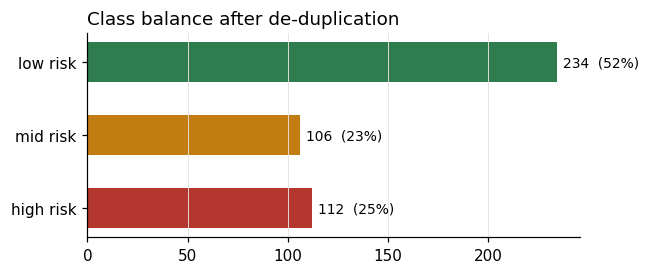

In [12]:
counts = df[TARGET].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(counts.index, counts.values, color=[COLORS[c] for c in counts.index], height=0.55)
for y, v in enumerate(counts.values):
    ax.text(v + 3, y, f"{v}  ({v / counts.sum():.0%})", va="center", fontsize=9)
ax.set_title("Class balance after de-duplication", loc="left")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 2. How vitals differ by risk level

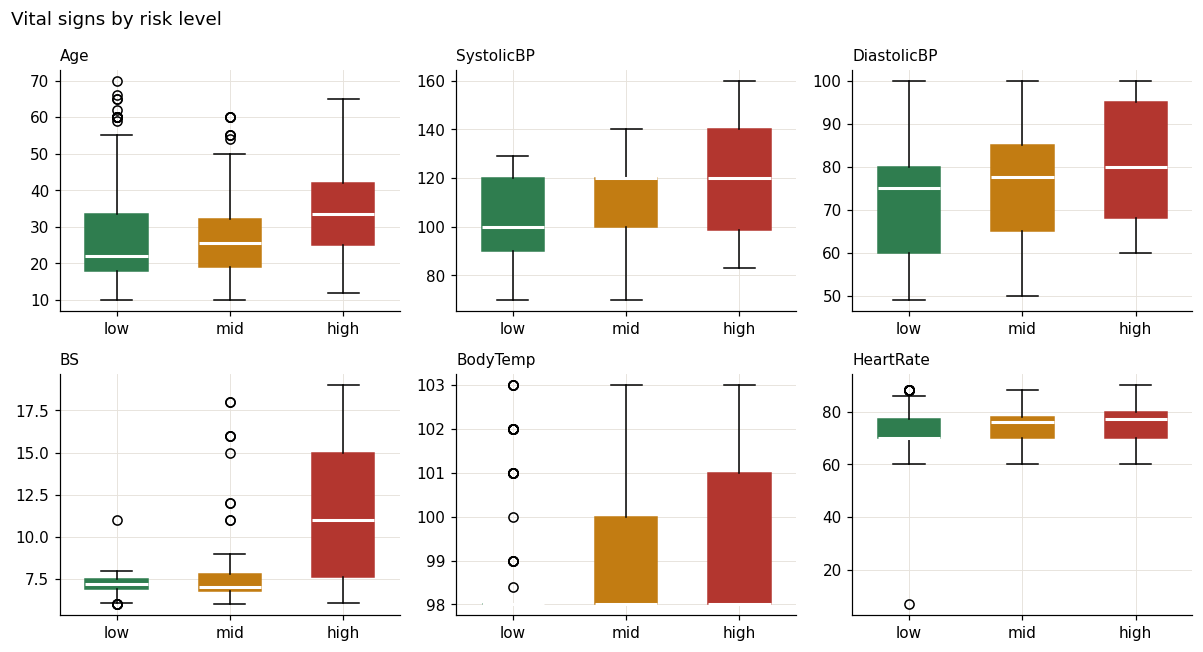

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, feat in zip(axes.flat, FEATURES):
    data = [df.loc[df[TARGET] == c, feat] for c in CLASSES]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops={"color": "white", "linewidth": 2})
    for patch, c in zip(bp["boxes"], CLASSES):
        patch.set_facecolor(COLORS[c]); patch.set_edgecolor(COLORS[c])
    ax.set_xticks([1, 2, 3], ["low", "mid", "high"])
    ax.set_title(feat, loc="left", fontsize=10)
fig.suptitle("Vital signs by risk level", x=0.01, ha="left")
plt.tight_layout(); plt.show()

Blood glucose and blood pressure are where clinical guidance would expect the clearest separation; the plots show how far that holds in this data.

## 3. The duplicate trap

Much of the raw file is exact duplicate rows. If duplicates are not removed, copies of the same record land in both training and test folds, so the model is partly graded on answers it has already seen. The comparison below shows how much that inflates scores.

In [14]:
raw_clean_labels = raw[FEATURES + [TARGET]].assign(**{TARGET: raw[TARGET].str.strip().str.lower()})
leaky = evaluate(raw_clean_labels).set_index("model")[["accuracy", "macro_f1"]]
honest = evaluate(df).set_index("model")[["accuracy", "macro_f1"]]
pd.concat({"with duplicates": leaky, "de-duplicated": honest}, axis=1).round(3)

with duplicates          de-duplicated         
                           accuracy macro_f1      accuracy macro_f1
model                                                              
Gradient Boosting             0.798    0.803         0.681    0.615
Random Forest                 0.818    0.822         0.673    0.616
Logistic Regression           0.603    0.604         0.588    0.547

The de-duplicated scores are the ones to trust, and the only ones reported from here on.

## 4. Model comparison

Five-fold stratified cross-validation. Models are ranked by **high-risk recall** first, because a missed high-risk pregnancy costs far more than an unnecessary referral.

In [15]:
results = evaluate(df)
results.round(3)

,model,accuracy,macro_f1,high_risk_recall,macro_f1_sd
0,Random Forest,0.673,0.616,0.775,0.019
1,Gradient Boosting,0.681,0.615,0.687,0.034
2,Logistic Regression,0.588,0.547,0.678,0.056


Random Forest: out-of-fold predictions

              precision    recall  f1-score   support

    low risk      0.744     0.795     0.769       234
    mid risk      0.378     0.292     0.330       106
   high risk      0.725     0.777     0.750       112

    accuracy                          0.673       452
   macro avg      0.616     0.621     0.616       452
weighted avg      0.653     0.673     0.661       452



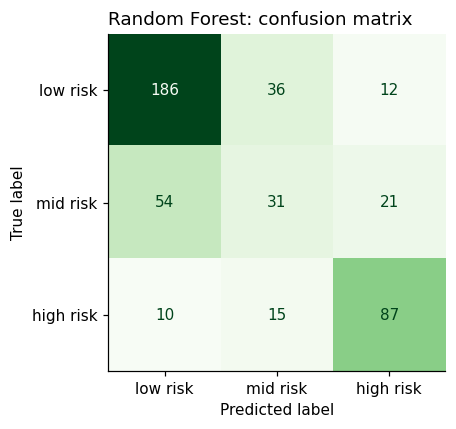

In [16]:
best = results.iloc[0]["model"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pred = cross_val_predict(candidates()[best], df[FEATURES], df[TARGET], cv=cv)
print(f"{best}: out-of-fold predictions\n")
print(classification_report(df[TARGET], pred, labels=CLASSES, digits=3))
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(df[TARGET], pred, labels=CLASSES, cmap="Greens", ax=ax, colorbar=False)
ax.set_title(f"{best}: confusion matrix", loc="left"); ax.grid(False)
plt.tight_layout(); plt.show()

## 5. What drives the predictions

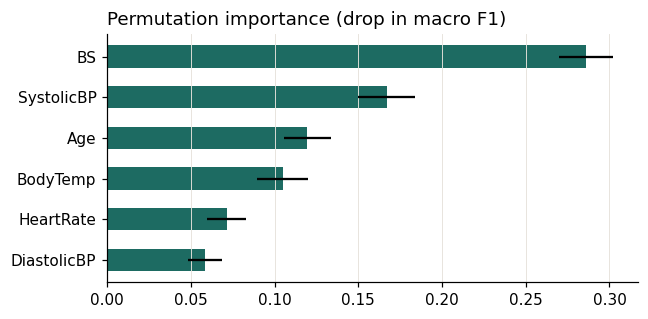

In [17]:
model = train(df, best)
imp = permutation_importance(model, df[FEATURES], df[TARGET], n_repeats=20,
                             random_state=SEED, scoring="f1_macro")
order = np.argsort(imp.importances_mean)
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(np.array(FEATURES)[order], imp.importances_mean[order],
        xerr=imp.importances_std[order], color="#1d6b62", height=0.55)
ax.set_title("Permutation importance (drop in macro F1)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 6. Save the model for the API

In [18]:
path = save(model, best, results.iloc[0].drop("model").round(4).to_dict())
print(f"Saved to {path}. Start the API with: uvicorn api.main:app --reload")

Saved to /home/injinia/Desktop/mamarisk/mamarisk/model/mamarisk.joblib. Start the API with: uvicorn api.main:app --reload


## Limitations

- **Small and from one setting.** Once duplicates are removed, only a few hundred records remain, all from one region in Bangladesh. Performance in Kenyan maternity units is unknown until tested on local data.
- **No time dimension.** Each row is one snapshot. Real deterioration shows up as trends across visits, which this data cannot capture.
- **Label provenance.** Risk labels come from the original study's clinicians, and the labelling criteria are not fully documented.
- **Not a clinical tool.** This is a screening prototype meant to support health workers' judgement, not to replace it.

## Next steps

- Validate against data from a Kenyan facility, with ethics approval.
- Calibrate probabilities and set the decision threshold together with clinicians.
- Add trend features from repeated antenatal visits.